# 08 — Compare controllers, check robustness, and assess progress

**Goal:** answer whether the idea is promising, using matched simulated sessions.
We run 500 validation sessions per condition and compare all required Stage-1 baselines.
This notebook defaults to an **initial 28-condition study**, not the entire factorial sweep.
It covers all four fatigue stories, all four nonzero beta values, all four sensitivity distributions, multiple recovery/signal/time settings, and a 300-step session.
An extra zero-beta lapse control separates disengagement from fatigue.
Each sensitivity axis is initially varied separately. These runs do not cover every interaction.

The complete factorial manifest contains 7,812 conditions (including both session lengths).
Set `RUN_FULL_GRID = True` below to run it, with caching after each completed condition.
A provisional choice from the initial study is clearly labelled.
Test annotators and final-test image evaluation remain reserved.

**Update (22 Nov):** the full grid was later run with [run_full_grid.py](../scripts/run_full_grid.py) on the frozen code (`outputs/full_grid/2954f9bca0`), not in this notebook, so this notebook keeps `RUN_FULL_GRID = False` and its selection below is still labelled provisional. The full grid selected QMDP with the same rule. The final test on test annotators and final-test images is reported in [notebook 11](11_final_test_results.ipynb).
Code: [study.py](../src/eval/study.py), [stage1.py](../src/eval/stage1.py).

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
if str(project) not in sys.path:
    sys.path.insert(0, str(project))
from src.common import save_run, load_calibration, load_contexts
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

def show_plot(name):
    plt.tight_layout()
    plt.savefig(folder / f'{name}.png', dpi=150)
    plt.show()

## 1. Choose the run coverage and load the trained controller
The full factorial run is much larger than the initial study. The manifest records the exact outstanding combinations; equivalent zero-fatigue settings are collapsed into M-None; zero-beta lapse conditions stay separate. Lambda is 1.0 bits per second for controller selection, chosen by the lambda sweep (`scripts/run_lambda_sweep.py`, training people and tuning seeds only). A separate frontier below varies lambda.

In [2]:
import torch
from dataclasses import replace
from src.control.dqn import make_network
from src.eval.study import run_study, full_cases, select_controller, comparison_table
from src.eval.stage1 import benchmark, summarize
from src.eval.stats import paired_difference
from src.sim.fatigue import Scenario
RUN_FULL_GRID = False
assert json.loads((project / 'outputs/sim_validation/gate.json').read_text())['passed']
contexts = load_contexts()
dqn_info = json.loads((project / 'outputs/dqn_latest.json').read_text())
controller = make_network()
controller.load_state_dict(torch.load(project / dqn_info['folder'] / 'controller.pt', weights_only=True))
controller.eval()
print('Full factorial conditions:', len(full_cases()))

Full factorial conditions: 7812


## 2. Run paired comparisons
Each condition has the same people and candidate stream across policies. Each context comes from the saved calibrated classifier snapshots.

In [3]:
study, folder = run_study(contexts, controller, full=RUN_FULL_GRID, episodes=500)
condition_summary = study.groupby(['case', 'model', 'beta', 'policy'], sort=False)[['reward', 'information', 'seconds', 'error_rate']].mean().reset_index()
condition_summary.to_csv(folder / 'condition_summary.csv', index=False)
print('Completed conditions:', study.case.nunique(), '| sessions per policy per condition:', 500)

Case 1/28: no_fatigue
Case 2/28: Markov_beta_0.5
Case 3/28: Markov_beta_1
Case 4/28: Markov_beta_2
Case 5/28: Markov_beta_3
Case 6/28: FALCON_beta_0.5
Case 7/28: FALCON_beta_1
Case 8/28: FALCON_beta_2
Case 9/28: FALCON_beta_3
Case 10/28: Lapse_beta_0.5
Case 11/28: Lapse_beta_1
Case 12/28: Lapse_beta_2
Case 13/28: Lapse_beta_3
Case 14/28: distribution_uniform
Case 15/28: distribution_mixture
Case 16/28: distribution_gamma
Case 17/28: recovery_0.2
Case 18/28: recovery_0.5
Case 19/28: signal_0.5
Case 20/28: signal_2.0
Case 21/28: cost_0.25_0.6
Case 22/28: cost_0.5_0.6
Case 23/28: cost_0.35_0.5
Case 24/28: cost_0.35_0.75
Case 25/28: long_session_300
Case 26/28: lapse_without_fatigue
Case 27/28: fast_stress_markov_beta_1
Case 28/28: fast_stress_markov_beta_2
Completed conditions: 28 | sessions per policy per condition: 500


## 3. Apply the controller comparison rule
Average net reward across nonzero-fatigue conditions. For the initial study, use the balanced core set (three fatigue worlds × four nonzero betas). Average within each matched episode first, then compute the mean and standard error. Within one standard error of the best, prefer QMDP, then the grid planner, then DQN.
Until the full grid is complete, the selected controller is **provisional**. *(Update, 22 Nov: the full grid has since been run with `scripts/run_full_grid.py` and selected QMDP; see notebook 11.)*

,mean,sem
policy,,
dqn,-67.738,2.626
grid,-77.026,2.904
qmdp,-45.477,2.391


provisional initial-study choice: qmdp


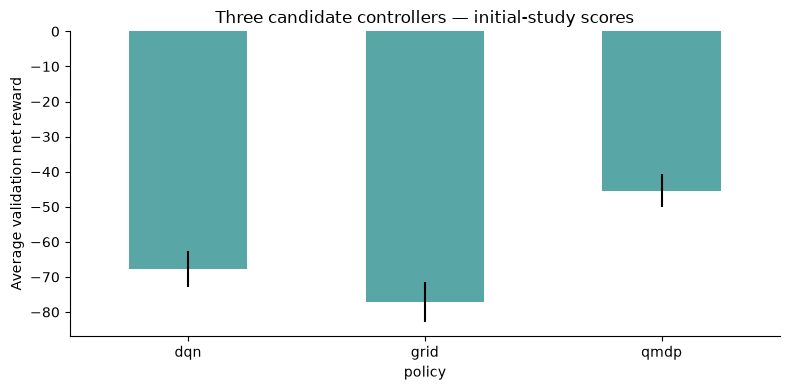

In [4]:
winner, scores = select_controller(study, full=RUN_FULL_GRID)
selection = {'controller': winner, 'status': 'full-grid validation selection' if RUN_FULL_GRID else 'provisional initial-study choice',
    'completed_conditions': int(study.case.nunique()), 'full_grid_conditions': len(full_cases()),
    'test_annotators_evaluated': False, 'final_test_images_evaluated': False}
(folder / 'selection.json').write_text(json.dumps(selection, indent=2))
display(scores.round(3))
print(selection['status'] + ':', winner)
scores['mean'].plot.bar(yerr=scores['sem'] * 1.96, color='#58a6a6', rot=0)
plt.ylabel('Average validation net reward')
plt.title('Three candidate controllers — initial-study scores' if not RUN_FULL_GRID else 'Full-grid selection scores')
show_plot('01_controller_selection')

## 4. Compare fatigue stories
Benefits in the main Markov world do not automatically carry over to warm-up or disengagement. Report each separately.

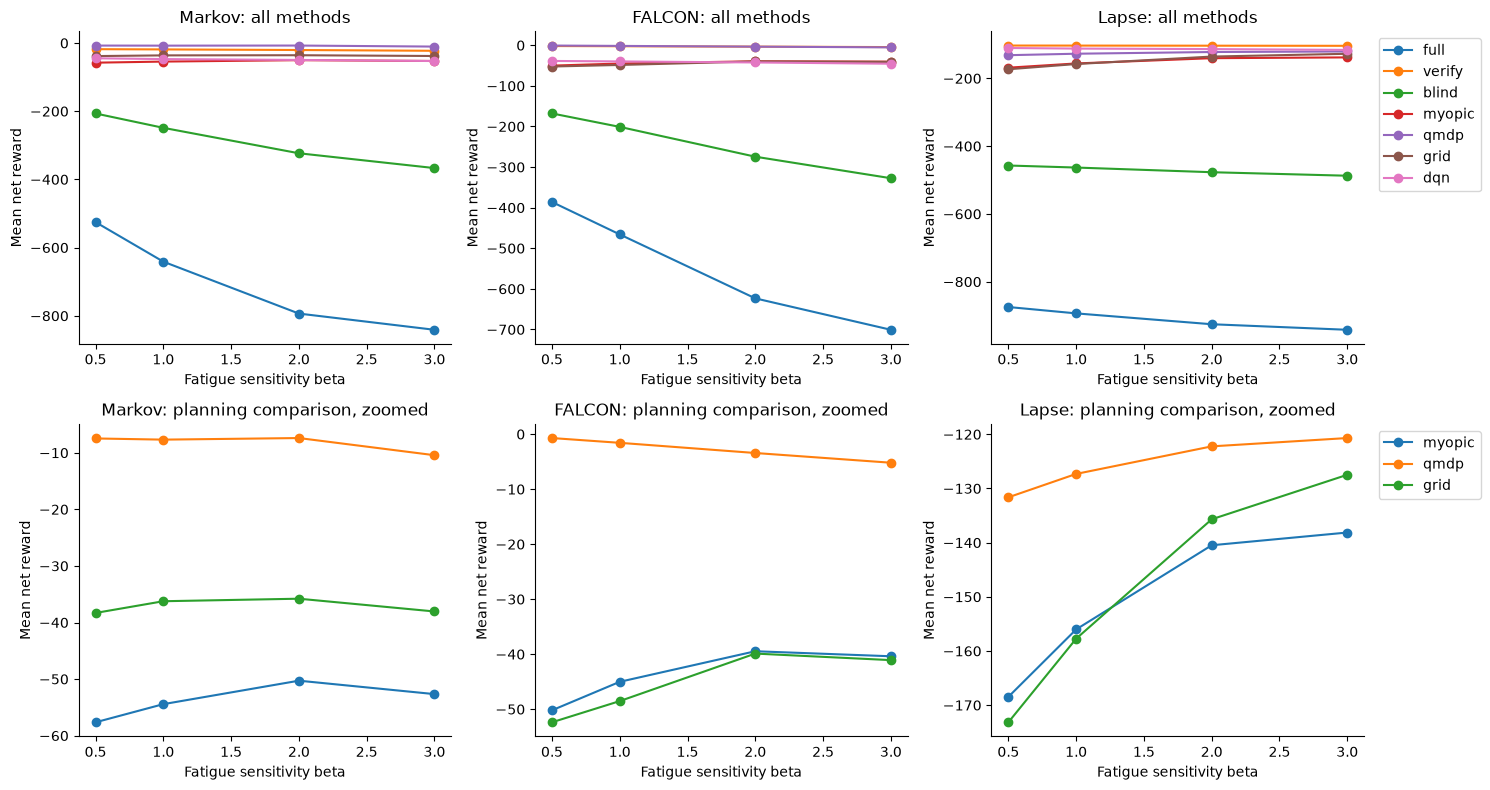

In [5]:
core = study[study.purpose.isin(['core', 'full_grid'])]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, model_name in enumerate(['Markov', 'FALCON', 'Lapse']):
    for row, policies in enumerate([['full', 'verify', 'blind', 'myopic', 'qmdp', 'grid', 'dqn'], ['myopic', 'qmdp', 'grid']]):
        for policy in policies:
            means = core[(core.model == model_name) & (core.policy == policy)].groupby('beta').reward.mean()
            axes[row, column].plot(means.index, means, 'o-', label=policy)
        axes[row, column].set(title=f'{model_name}: ' + ('all methods' if row == 0 else 'planning comparison, zoomed'),
            xlabel='Fatigue sensitivity beta', ylabel='Mean net reward')
axes[0, -1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1, -1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_plot('02_fatigue_story_comparisons')

## 5. Check whether the selected controller beats every required baseline
These are unadjusted paired-bootstrap 95% intervals on development comparisons.
They support diagnosis and selection; they are not independent confirmatory results after selection.
Every comparator must have a positive lower bound for a condition to pass the stated H2 test.

In [6]:
paired = comparison_table(study, winner)
paired.to_csv(folder / 'paired_comparisons.csv', index=False)
# Review fix: greedy, greedy-plus-rest and the fixed-model QMDP are not B1-B8 baselines.
required = paired[~paired.second.isin(['myopic', 'rest_threshold', 'qmdp_fixed'])]
condition_checks = required.groupby(['case', 'model', 'beta']).ci_low.min().rename('worst_baseline_ci_low').reset_index()
condition_checks['beats_all_baselines'] = condition_checks.worst_baseline_ci_low > 0
display(condition_checks.round(3))
greedy_checks = paired[paired.second == 'myopic']
display(greedy_checks[['case', 'difference', 'ci_low', 'ci_high']].round(3))

,case,model,beta,worst_baseline_ci_low,beats_all_baselines
0,FALCON_beta_0.5,FALCON,0.5,0.500,True
1,FALCON_beta_1,FALCON,1.0,0.141,True
2,FALCON_beta_2,FALCON,2.0,-0.630,False
3,FALCON_beta_3,FALCON,3.0,-1.270,False
4,Lapse_beta_0.5,Lapse,0.5,-32.318,False
5,Lapse_beta_1,Lapse,1.0,-27.923,False
6,Lapse_beta_2,Lapse,2.0,-22.591,False
7,Lapse_beta_3,Lapse,3.0,-20.608,False
8,Markov_beta_0.5,Markov,0.5,6.107,True
9,Markov_beta_1,Markov,1.0,6.570,True


,case,difference,ci_low,ci_high
8,no_fatigue,0.000,0.000,0.000
19,Markov_beta_0.5,50.170,43.561,56.670
30,Markov_beta_1,46.756,40.362,53.233
41,Markov_beta_2,42.889,37.081,48.944
52,Markov_beta_3,42.229,36.256,48.447
63,FALCON_beta_0.5,49.492,47.087,51.979
74,FALCON_beta_1,43.443,41.361,45.660
85,FALCON_beta_2,36.037,34.315,37.899
96,FALCON_beta_3,35.183,33.491,37.034
107,Lapse_beta_0.5,36.836,30.990,42.703


## 6. Plot the advantage over the greedy controller
Planning should earn its extra complexity by improving on immediate-only choices.

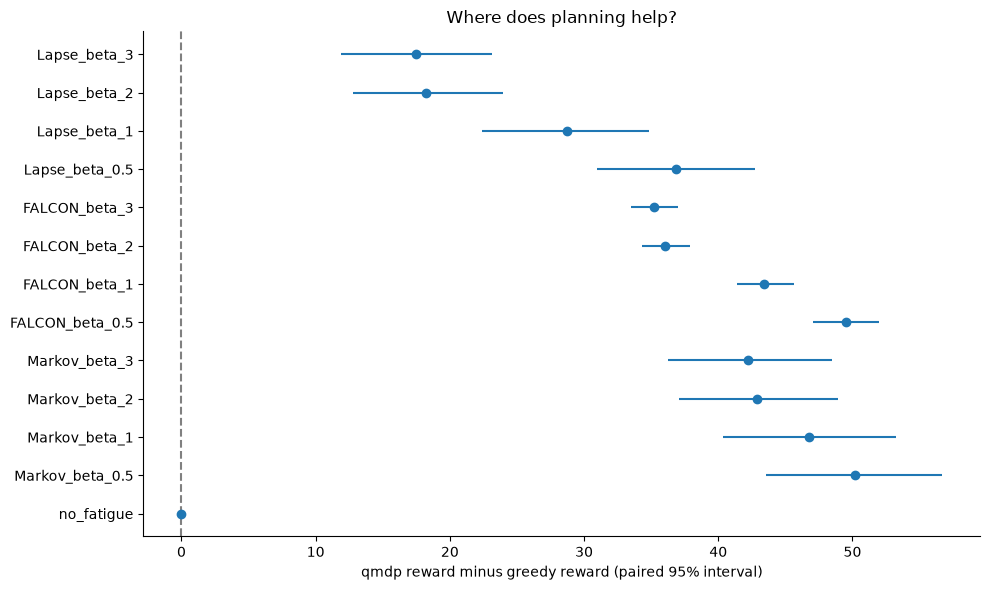

In [7]:
core_cases = set(core.case)
shown = greedy_checks[greedy_checks.case.isin(core_cases)].copy()
plt.figure(figsize=(10, 6))
plt.errorbar(shown.difference, shown.case, xerr=np.array([shown.difference - shown.ci_low, shown.ci_high - shown.difference]), fmt='o')
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel(f'{winner} reward minus greedy reward (paired 95% interval)')
plt.title('Where does planning help?')
show_plot('03_planning_advantages')

## 7. Look at distribution, recovery, signal, cost, and session-length sensitivity
Each displayed condition changes one axis from Markov beta=2. Changing signal quality also changes actual response-time growth in the specified simulator; it is not a pure observation-noise experiment. The full factorial grid is needed to check interactions.

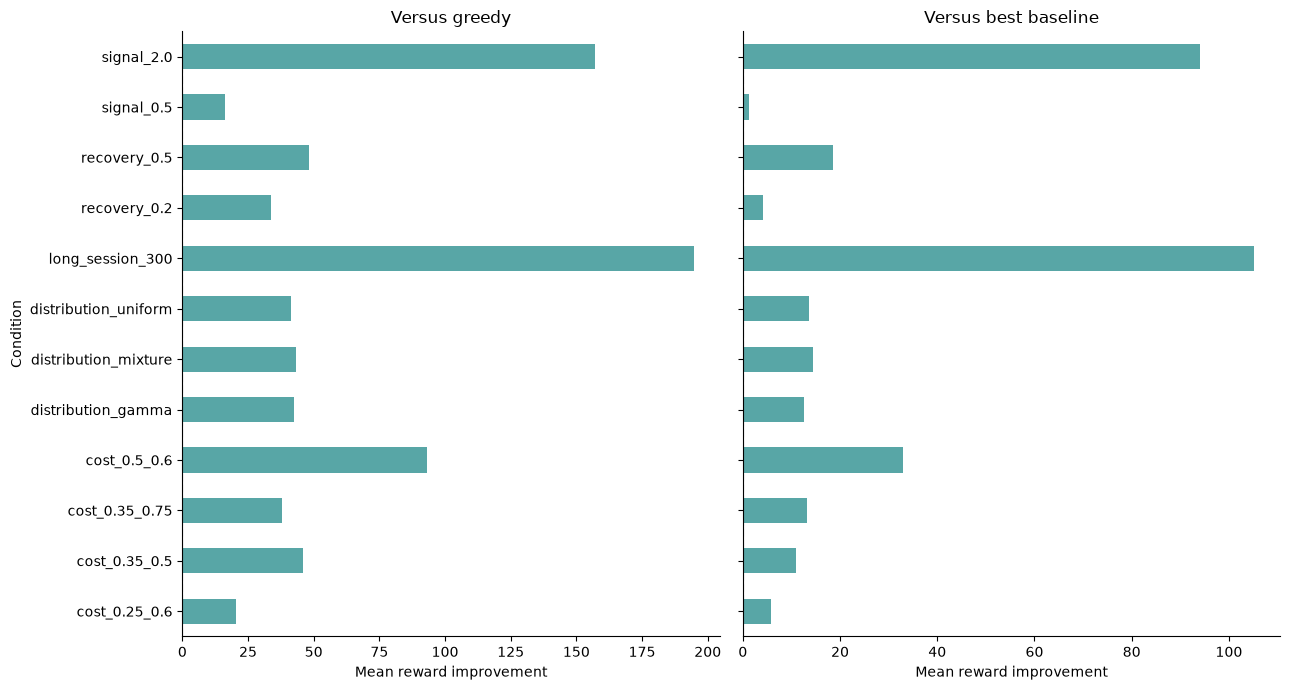

,Versus greedy,Versus best baseline
case,,
cost_0.25_0.6,20.29,5.83
cost_0.35_0.5,45.81,10.92
cost_0.35_0.75,37.84,13.13
cost_0.5_0.6,93.06,32.96
distribution_gamma,42.33,12.65
distribution_mixture,43.25,14.46
distribution_uniform,41.49,13.52
long_session_300,194.75,105.25
recovery_0.2,33.89,4.12


In [8]:
sensitivity = study[study.purpose == 'sensitivity']
if not sensitivity.empty:
    sensitivity_scores = sensitivity.groupby(['case', 'policy']).reward.mean().unstack()
    baseline_names = ['full', 'two_choice', 'verify', 'random', 'alternating', 'exp_decay', 'gap_workload', 'blind']
    best_baseline = sensitivity_scores[baseline_names].max(axis=1)
    gains = pd.DataFrame({'Versus greedy': sensitivity_scores[winner] - sensitivity_scores.myopic,
        'Versus best baseline': sensitivity_scores[winner] - best_baseline})
    fig, axes = plt.subplots(1, 2, figsize=(13, 7), sharey=True)
    for ax, name in zip(axes, gains.columns):
        gains[name].plot.barh(ax=ax, color='#58a6a6')
        ax.axvline(0, color='gray', linestyle='--')
        ax.set(xlabel='Mean reward improvement', title=name, ylabel='Condition')
    show_plot('04_sensitivity_checks')
    display(gains.round(2))
else:
    print('Full grid selected: slice the saved condition summary for sensitivity views.')

## 8. Deliberately use the wrong planning model
Plan with Markov beta=2, then change the true beta, fatigue speed, or fatigue story. This keeps the controller's assumed parameters fixed. The learned DQN remains frozen too.
The five-state planner does not explicitly model lapse or cumulative FALCON workload.

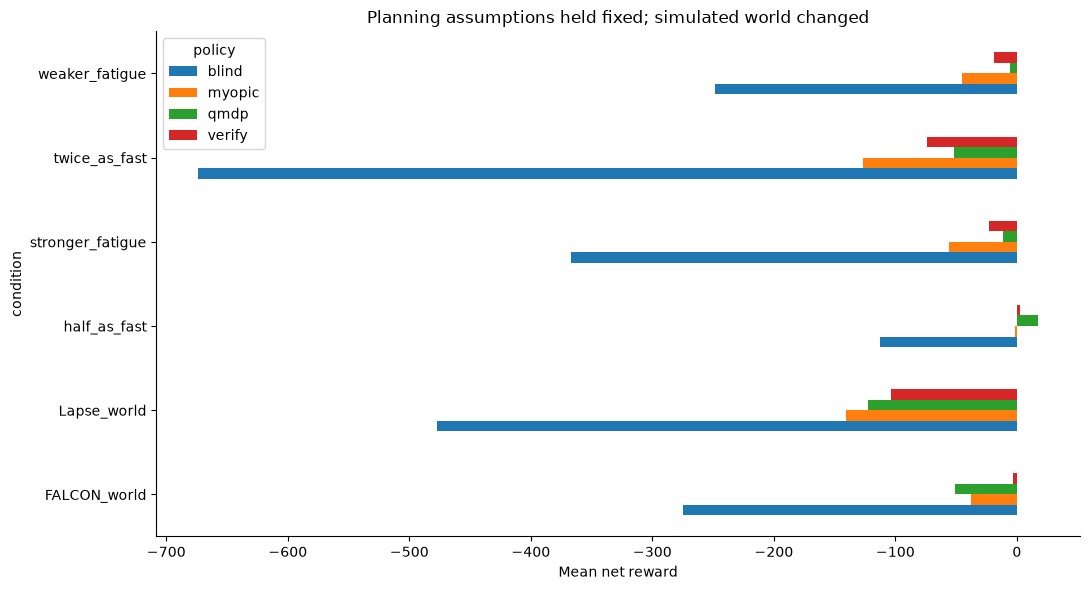

,condition,first,second,difference,ci_low,ci_high
0,FALCON_world,qmdp,myopic,-13.007,-16.305,-9.774
1,Lapse_world,qmdp,myopic,18.254,12.780,23.956
2,half_as_fast,qmdp,myopic,19.067,15.076,23.065
3,stronger_fatigue,qmdp,myopic,45.107,39.271,51.615
4,twice_as_fast,qmdp,myopic,74.393,66.567,82.169
5,weaker_fatigue,qmdp,myopic,40.051,34.461,45.858


In [9]:
assumed = Scenario(beta=2)
robustness_cases = {'weaker_fatigue': replace(assumed, beta=1), 'stronger_fatigue': replace(assumed, beta=3),
    'twice_as_fast': replace(assumed, speed=2), 'half_as_fast': replace(assumed, speed=.5),
    'FALCON_world': replace(assumed, model='FALCON'), 'Lapse_world': replace(assumed, model='Lapse')}
robustness_tables = []
robustness_policies = list(dict.fromkeys([winner, 'qmdp', 'myopic', 'blind', 'verify']))
for name, actual in robustness_cases.items():
    table, path = benchmark(contexts, actual, robustness_policies, dqn=controller, assumed=assumed, episodes=500, stage='robustness')
    table['condition'] = name
    robustness_tables.append(table)
robustness = pd.concat(robustness_tables, ignore_index=True)
robustness.to_csv(folder / 'robustness_episodes.csv.gz', index=False)
robustness.groupby(['condition', 'policy']).reward.mean().unstack().plot.barh(figsize=(11, 6))
plt.xlabel('Mean net reward')
plt.title('Planning assumptions held fixed; simulated world changed')
show_plot('05_robustness')
robustness_pairs = pd.DataFrame([{'condition': name, **paired_difference(group, winner, 'myopic')}
    for name, group in robustness.groupby('condition')])
robustness_pairs.to_csv(folder / 'robustness_paired_comparisons.csv', index=False)
display(robustness_pairs.round(3))

## 9. Trace achieved information versus time
Lambda sets the time charge. Different lambdas produce different behaviours.
This plot shows achieved operating points, not a proven optimal frontier.
We omit DQN here because it was trained at one lambda only.

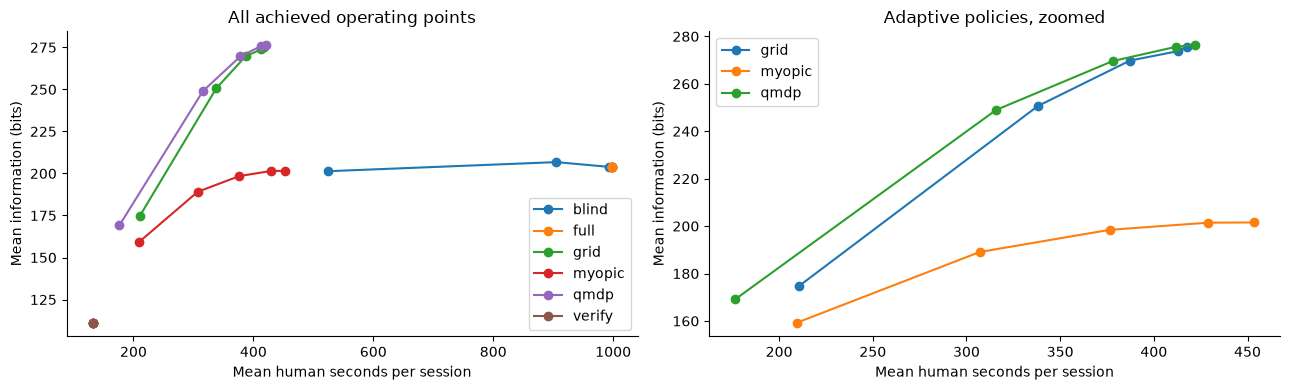

In [10]:
frontier_rows = []
for lam in [.05, .1, .25, .5, 1.]:
    condition = Scenario(beta=2, lam=lam)
    table, path = benchmark(contexts, condition, ['full', 'verify', 'blind', 'myopic', 'qmdp', 'grid'], episodes=500, stage='frontier')
    summary = summarize(table).reset_index()
    summary['lambda'] = lam
    frontier_rows.append(summary)
frontier = pd.concat(frontier_rows, ignore_index=True)
frontier.to_csv(folder / 'information_time_frontier.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for policy, group in frontier.groupby('policy'):
    group = group.sort_values('seconds')
    axes[0].plot(group.seconds, group.information, 'o-', label=policy)
    if policy in ['myopic', 'qmdp', 'grid']:
        axes[1].plot(group.seconds, group.information, 'o-', label=policy)
for ax, title in zip(axes, ['All achieved operating points', 'Adaptive policies, zoomed']):
    ax.set(xlabel='Mean human seconds per session', ylabel='Mean information (bits)', title=title)
    ax.legend()
show_plot('06_information_time_tradeoff')

## 10. Save a candid project assessment
Positive simulation results are promising under the tested assumptions. They cannot yet establish real-human benefits, better classifier accuracy, or fewer seconds to reach target accuracy.
Those require the full grid, frozen controller selection, Stage 2, and final held-out reporting.

*Update (22 Nov): all of these have since been done; the full-grid selection and the final held-out results are in notebook 11.*

In [11]:
markov = condition_checks[(condition_checks.model == 'Markov') & (condition_checks.beta >= 1)]
falcon = condition_checks[(condition_checks.model == 'FALCON') & (condition_checks.beta >= 1)]
planning = greedy_checks[(greedy_checks.model == 'Markov') & (greedy_checks.beta >= 1)]
zero = summarize(study[study.model == 'None'])
zero_baselines = ['full', 'two_choice', 'verify', 'random', 'alternating', 'exp_decay', 'gap_workload', 'blind']
best_zero = zero.loc[zero_baselines].reward.idxmax()
zero_difference = float(zero.loc[winner, 'reward'] - zero.loc[best_zero, 'reward'])
core_markov_gaps = greedy_checks[greedy_checks.case.isin(core_cases) & greedy_checks.model.eq('Markov') & (greedy_checks.beta >= 1)].groupby('beta').difference.mean().sort_index()
falcon_planning = greedy_checks[greedy_checks.case.isin(core_cases) & greedy_checks.model.eq('FALCON') & (greedy_checks.beta >= 1)]
assessment = {**selection, 'markov_h2_passes': int(markov.beats_all_baselines.sum()), 'markov_h2_conditions': len(markov),
    'falcon_h2_passes': int(falcon.beats_all_baselines.sum()), 'falcon_h2_conditions': len(falcon),
    'markov_planning_positive_intervals': int((planning.ci_low > 0).sum()),
    'markov_planning_conditions': len(planning), 'no_fatigue_reward_difference_vs_best_baseline': zero_difference,
    'core_markov_planning_gap_grows_with_beta': bool((np.diff(core_markov_gaps.to_numpy()) > 0).all()),
    'falcon_planning_positive_intervals': int((falcon_planning.ci_low > 0).sum()),
    'falcon_planning_conditions': len(falcon_planning),
    'robustness_beats_myopic_positive_intervals': int((robustness_pairs.ci_low > 0).sum()),
    'robustness_conditions': len(robustness_pairs),
    'scope': 'simulated information/time only; validation comparisons; no Stage-2 accuracy or final tests'}
(folder / 'assessment.json').write_text(json.dumps(assessment, indent=2))
(project / 'outputs/stage1_latest.json').write_text(json.dumps({'folder': str(folder.relative_to(project)), 'assessment': assessment}, indent=2))
display(pd.Series(assessment, name='result').to_frame())
print('Next: freeze selection after the full grid, then build the full active-learning loop.')
print(f"Recoverable-fatigue conditions beating every baseline: {assessment['markov_h2_passes']}/{assessment['markov_h2_conditions']}")
print(f"FALCON conditions beating every baseline: {assessment['falcon_h2_passes']}/{assessment['falcon_h2_conditions']}")
print(f"FALCON conditions beating greedy with a positive interval: {assessment['falcon_planning_positive_intervals']}/{assessment['falcon_planning_conditions']}")
print('Does the core Markov planning advantage grow with beta?', assessment['core_markov_planning_gap_grows_with_beta'])
print('These are preliminary simulation findings. Classifier accuracy versus human time is still untested.')

,result
controller,qmdp
status,provisional initial-study choice
completed_conditions,28
full_grid_conditions,7812
test_annotators_evaluated,False
final_test_images_evaluated,False
markov_h2_passes,16
markov_h2_conditions,17
falcon_h2_passes,1
falcon_h2_conditions,3


Next: freeze selection after the full grid, then build the full active-learning loop.
Recoverable-fatigue conditions beating every baseline: 16/17
FALCON conditions beating every baseline: 1/3
FALCON conditions beating greedy with a positive interval: 3/3
Does the core Markov planning advantage grow with beta? False
These are preliminary simulation findings. Classifier accuracy versus human time is still untested.
